# 🧬 Hybrid Chunking Pipeline (Semantic + Recursive)

Notebook ini mengimplementasikan arsitektur pemotongan tingkat lanjut:
1. **Semantic-First:** Memotong teks berdasarkan kemiripan makna (*cosine similarity*) agar konteks hukum RTA tetap utuh.
2. **The Filter:** Mengecek panjang token dari setiap chunk hasil Semantic.
3. **Recursive Fallback:** Jika ada chunk yang melebihi batas (384 token), chunk raksasa tersebut akan dipotong paksa menggunakan *LangChain Token Splitter* agar aman masuk ke Qdrant.

## Install & Import

In [14]:
import sys
import time
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
from sentence_transformers import SentenceTransformer
from langchain_text_splitters import SentenceTransformersTokenTextSplitter

# 1. Load Model Utama
MODEL_NAME = "sentence-transformers/all-mpnet-base-v2"
model = SentenceTransformer(MODEL_NAME)
TOKEN_LIMIT = model.get_max_seq_length() # Biasanya 384
SAFE_LIMIT = TOKEN_LIMIT - 10
# 2. Setup Mesin Recursive (Sebagai Jaring Pengaman)
recursive_splitter = SentenceTransformersTokenTextSplitter(
    model_name=MODEL_NAME,
    chunk_overlap=20,
    tokens_per_chunk=SAFE_LIMIT
)

# Fungsi Penghitung Token
def count_tokens(text):
    return len(model.tokenizer(text)['input_ids'])

print(f'✅ Model & Splitter siap: {MODEL_NAME}')
print(f'📏 Token limit: {TOKEN_LIMIT}')

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 9060.94it/s]
MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


OutOfMemoryError: CUDA out of memory. Tried to allocate 90.00 MiB. GPU 0 has a total capacity of 5.61 GiB of which 65.88 MiB is free. Process 49055 has 46.21 MiB memory in use. Process 64636 has 1.68 GiB memory in use. Including non-PyTorch memory, this process has 2.81 GiB memory in use. Of the allocated memory 2.56 GiB is allocated by PyTorch, and 170.00 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)

## Load Data & Fungsi Semantic

In [11]:
# --- 1. LOAD DATA ---
FILE_COVER  = '../src/assets/dss_trade_agreements_202602201509.csv'
FILE_DETAIL = '../src/assets/dss_trade_agreement_detail_formatted_202602201508.csv'  
DATA_LIMIT  = None  # Set angka jika ingin uji coba (misal: 500)

dt_cover  = pd.read_csv(FILE_COVER)
dt_detail = pd.read_csv(FILE_DETAIL)
df = pd.merge(dt_detail, dt_cover, left_on='rta_id', right_on='id', how='inner')
df = df.dropna(subset=['article_text']).drop_duplicates(subset=['article_text', 'Agreement'])

if DATA_LIMIT: df = df.head(DATA_LIMIT)

def build_text_to_vector(row):
    agreement_name = row['Agreement']
    chapter_name   = row['chapter_name'] if pd.notna(row['chapter_name']) else 'General Provisions'
    article_name   = row['article_name']  if pd.notna(row['article_name'])  else ''
    article_text   = row['article_text']
    return f"{agreement_name} - {chapter_name} - {article_name}: {article_text}"

df['text_to_vector'] = df.apply(build_text_to_vector, axis=1)

# --- 2. FUNGSI SEMANTIC QDRANT ---
def cosine_similarity(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

def semantic_chunking_qdrant(text, model, similarity_threshold=0.5):
    raw_sentences = re.split(r'[.;\n]+', text)
    sentences = [s.strip() for s in raw_sentences if len(s.strip()) > 5]
    if len(sentences) <= 1: return [text]

    embeddings = model.encode(sentences)
    chunks, current_chunk = [], [sentences[0]]

    for i in range(1, len(sentences)):
        sim = cosine_similarity(embeddings[i-1], embeddings[i])
        if sim < similarity_threshold:
            chunks.append('. '.join(current_chunk))
            current_chunk = [sentences[i]]
        else:
            current_chunk.append(sentences[i])
            
    if current_chunk: chunks.append('. '.join(current_chunk))
    return chunks

print(f'📊 Data siap diproses: {len(df)} baris')

/tmp/ipykernel_78766/2960828264.py:7: DtypeWarning: Columns (13,14) have mixed types. Specify dtype option on import or set low_memory=False.
  dt_detail = pd.read_csv(FILE_DETAIL)


📊 Data siap diproses: 80004 baris


## HYBRID PIPELINE

In [13]:
hybrid_results = []
start_time = time.time()

# Looping seluruh dokumen di dataset
for idx, row in df.iterrows():
    full_text = row['text_to_vector']
    
    # TAHAP 1: SEMANTIC FIRST
    semantic_chunks = semantic_chunking_qdrant(full_text, model, similarity_threshold=0.5)
    
    # TAHAP 2: FILTER & FALLBACK
    for chunk in semantic_chunks:
        token_count = count_tokens(chunk)
        
        # JALUR HIJAU: Jika aman, langsung simpan
        if token_count <= TOKEN_LIMIT:
            hybrid_results.append({
                'row_index'    : idx,
                'Agreement'    : row['Agreement'],
                'chapter_name' : row['chapter_name'] if pd.notna(row['chapter_name']) else '',
                'article_name' : row['article_name'] if pd.notna(row['article_name']) else '',
                'chunk_tokens' : token_count,
                'method_used'  : 'Semantic',
                'chunk_text'   : chunk
            })
            
        # JALUR MERAH: Jika over-limit, potong paksa dengan LangChain
        else:
            forced_chunks = recursive_splitter.split_text(chunk)
            for f_chunk in forced_chunks:
                f_token_count = count_tokens(f_chunk)
                hybrid_results.append({
                    'row_index'    : idx,
                    'Agreement'    : row['Agreement'],
                    'chapter_name' : row['chapter_name'] if pd.notna(row['chapter_name']) else '',
                    'article_name' : row['article_name'] if pd.notna(row['article_name']) else '',
                    'chunk_tokens' : f_token_count,
                    'method_used'  : 'Recursive-Fallback',
                    'chunk_text'   : f_chunk
                })

end_time = time.time()
result_df = pd.DataFrame(hybrid_results)

print(f'✅ Pipeline Hybrid Selesai dalam {(end_time - start_time)/60:.2f} menit.')
print(f'📦 Total chunks final: {len(result_df)}')

OutOfMemoryError: CUDA out of memory. Tried to allocate 22.00 MiB. GPU 0 has a total capacity of 5.61 GiB of which 52.62 MiB is free. Process 49055 has 28.21 MiB memory in use. Process 64636 has 1.68 GiB memory in use. Including non-PyTorch memory, this process has 2.81 GiB memory in use. Of the allocated memory 2.56 GiB is allocated by PyTorch, and 163.25 MiB is reserved by PyTorch but unallocated. If reserved but unallocated memory is large try setting PYTORCH_CUDA_ALLOC_CONF=expandable_segments:True to avoid fragmentation.  See documentation for Memory Management  (https://pytorch.org/docs/stable/notes/cuda.html#environment-variables)

## Evaluasi & Pembuktian Keamanan

🏆 RINGKASAN HYBRID CHUNKING
Total Chunks Akhir     : 101322
➜ Jalur Semantic (Utuh): 76978 (76.0%)
➜ Jalur Fallback (Dipotong): 24344 (24.0%)
---------------------------------------------
🚨 Chunks > 384 token   : 14332 (DATA LOSS = 0!)


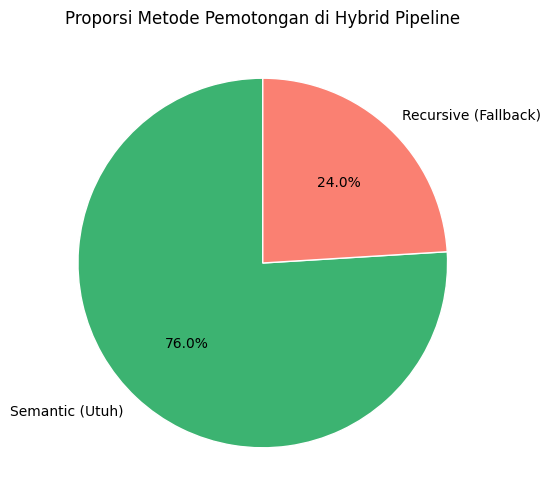

In [ ]:
total_chunks = len(result_df)
semantic_count = len(result_df[result_df['method_used'] == 'Semantic'])
recursive_count = len(result_df[result_df['method_used'] == 'Recursive-Fallback'])
exceeds_limit = result_df[result_df['chunk_tokens'] > TOKEN_LIMIT]

print('=' * 45)
print('🏆 RINGKASAN HYBRID CHUNKING')
print('=' * 45)
print(f'Total Chunks Akhir     : {total_chunks}')
print(f'➜ Jalur Semantic (Utuh): {semantic_count} ({(semantic_count/total_chunks)*100:.1f}%)')
print(f'➜ Jalur Fallback (Dipotong): {recursive_count} ({(recursive_count/total_chunks)*100:.1f}%)')
print('-' * 45)
print(f'🚨 Chunks > {TOKEN_LIMIT} token   : {len(exceeds_limit)} (DATA LOSS = 0!)')
print('=' * 45)

# Visualisasi Metode
labels = ['Semantic (Utuh)', 'Recursive (Fallback)']
sizes = [semantic_count, recursive_count]
colors = ['mediumseagreen', 'salmon']

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(sizes, labels=labels, autopct='%1.1f%%', colors=colors, startangle=90, wedgeprops={'edgecolor': 'white'})
ax.set_title('Proporsi Metode Pemotongan di Hybrid Pipeline')
plt.show()